## Filtering and trimming messages
### Goal
- Now, we can start using these concepts with models in LangGraph!
- In the next few sessions, we'll build towards a chatbot that has long-term memory.
- Because our chatbot will use messages, let's first talk a bit more about advanced ways to work with messages in graph state.


### Messages as State

In [1]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage 

messages = [AIMessage(f"So you said you were researching ocean mammals?", name="Bot")]
messages.append(HumanMessage(f"Yes, I know about whales. But what others should I learn about?", name="Bilal"))


for m in messages:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?


In [3]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen2.5:7b")

model.invoke("What is capital of france?")

AIMessage(content='The capital of France is Paris.', additional_kwargs={}, response_metadata={'model': 'qwen2.5:7b', 'created_at': '2026-11-05T20:55:58.8522394Z', 'done': True, 'done_reason': 'stop', 'total_duration': 791004300, 'load_duration': 330597500, 'prompt_eval_count': 35, 'prompt_eval_duration': 316936000, 'eval_count': 8, 'eval_duration': 121691000, 'logprobs': None, 'model_name': 'qwen2.5:7b', 'model_provider': 'ollama'}, id='lc_run--01a1ad7f-376a-7592-a900-8466c6946cf0-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 35, 'output_tokens': 8, 'total_tokens': 43})

In [5]:
model.invoke(messages).content

'Certainly! Besides whales, there are several other fascinating ocean mammals that you might want to learn about. Here are some notable ones:\n\n1. **Dolphins**: Known for their intelligence and playful behavior, dolphins are highly social and can be found in various parts of the world\'s oceans. They come in many species, including bottlenose dolphins, spinner dolphins, and orcas (killer whales).\n\n2. **Pilot Whales**: These are part of the dolphin family but are typically larger than most other dolphins. They are known for their strong social bonds and are often seen in large pods.\n\n3. **Elephant Seals**: Known for their impressive size, these seals can grow to be over 13 feet long and weigh up to 4,000 pounds. They are well-known for their harem system where one dominant male mates with multiple females.\n\n4. **Sea Otters**: These are known for their thick fur, which is the densest of any mammal, and their playful behavior. They are often found along the coasts of the Pacific Oc

We run out chat model in a simple graph with MessageState.

In [6]:
from IPython.display import Image, display
from langgraph.graph import MessagesState
from langgraph.graph import StateGraph, START, END



In [7]:
# Node
def chat_model_node(state:MessagesState):
    return {
        "messages": model.invoke(state["messages"])
    }




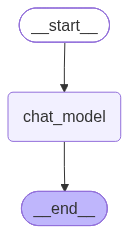

In [8]:
builder = StateGraph(MessagesState)


builder.add_node("chat_model", chat_model_node)

builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)

graph = builder.compile()



# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [9]:
output = graph.invoke(
    {
        "messages": messages
    }
)

for m in output["messages"]:
    m.pretty_print()


================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating subjects, and beyond whales, there are many other species worth learning about. Here are a few key groups and species:

1. **Dolphins and Porpoises**:
   - **Common Dolphins**: Known for their vibrant coloration and playful behavior.
   - **Bottlenose Dolphins**: Popular in marine parks and known for their intelligence and adaptability.
   - **Porpoises**: Smaller than dolphins, these include the Harbour Porpoise and Dall's Porpoise.

2. **Seals and Sea Lions**:
   - **Hooded Seals**: Known for their distinctive inflatable nose skin.
   - **California Sea Lions**: Often se

## Reducer

- A practical challenge when working with messages is managing long-running conversations.
- Long-running conversations result in high token usage and latency if we are not careful, because we pass a growing list of messages to the model.
- We have few ways to address this

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?


In [12]:
from langchain_core.messages import RemoveMessage


In [19]:
def filter_messages(state:MessagesState):
    # Delete all but except 2 most recent messages
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    return {
        "messages": delete_messages
    }

def chat_model_node(state: MessagesState):    
    return {"messages": [model.invoke(state["messages"])]}

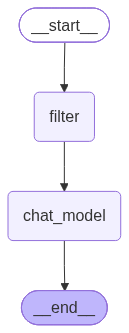

In [20]:
# Build graph
builder = StateGraph(MessagesState)
builder.add_node("filter", filter_messages)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "filter")
builder.add_edge("filter", "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
# Message list with a preamble
messages = [AIMessage("Hi.", name="Bot", id="1")]
messages.append(HumanMessage("Hi.", name="Bilal", id="2"))
messages.append(AIMessage("So you said you were researching ocean mammals?", name="Bot", id="3"))
messages.append(HumanMessage("Yes, I know about whales. But what others should I learn about?", name="Bilal", id="4"))

In [22]:
output = graph.invoke({
    "messages": messages
})

In [28]:
type(output)
print(output.items())   

dict_items([('messages', [AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Bot', id='3', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='Yes, I know about whales. But what others should I learn about?', additional_kwargs={}, response_metadata={}, name='Bilal', id='4'), AIMessage(content='Certainly! Ocean mammals are fascinating and diverse, and there are several species beyond whales that you might find interesting to learn about. Here are a few key groups and some notable species within each:\n\n1. **Dolphins and Porpoises**\n   - **Bottlenose Dolphin (Tursiops truncatus)**: These are one of the most well-known dolphin species and are often seen in aquariums and dolphin shows.\n   - **Killer Whale (Orcinus orca)**: Despite the name, the killer whale is actually a dolphin and one of the most widely distributed marine mammals. They are highly intelligent and social.\n\n2. **Seals and Sea Lions**\n   - **H

In [29]:
for m in output["messages"]:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating and diverse, and there are several species beyond whales that you might find interesting to learn about. Here are a few key groups and some notable species within each:

1. **Dolphins and Porpoises**
   - **Bottlenose Dolphin (Tursiops truncatus)**: These are one of the most well-known dolphin species and are often seen in aquariums and dolphin shows.
   - **Killer Whale (Orcinus orca)**: Despite the name, the killer whale is actually a dolphin and one of the most widely distributed marine mammals. They are highly intelligent and social.

2. **Seals and Sea Lions**
   - **

## Filtering Messages

- If you don't need or want to modify the graph state, you can just filter the messages you pass to the chat model.

- For example, just pass in a filtered list: llm.invoke(messages[-1:]) to the model.

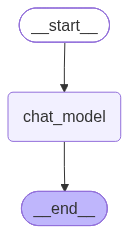

In [30]:
# Node
def chat_model_node(state: MessagesState):
    return {"messages": [model.invoke(state["messages"][-1:])]}

# Build graph
builder = StateGraph(MessagesState)
builder.add_node("chat_model", chat_model_node)
builder.add_edge(START, "chat_model")
builder.add_edge("chat_model", END)
graph = builder.compile()

# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [35]:
messages.append(output['messages'][-1])
messages


[AIMessage(content='Hi.', additional_kwargs={}, response_metadata={}, name='Bot', id='1', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Hi.', additional_kwargs={}, response_metadata={}, name='Bilal', id='2'),
 AIMessage(content='So you said you were researching ocean mammals?', additional_kwargs={}, response_metadata={}, name='Bot', id='3', tool_calls=[], invalid_tool_calls=[]),
 HumanMessage(content='Yes, I know about whales. But what others should I learn about?', additional_kwargs={}, response_metadata={}, name='Bilal', id='4'),
 AIMessage(content='Certainly! Ocean mammals are fascinating and diverse, and there are several species beyond whales that you might find interesting to learn about. Here are a few key groups and some notable species within each:\n\n1. **Dolphins and Porpoises**\n   - **Bottlenose Dolphin (Tursiops truncatus)**: These are one of the most well-known dolphin species and are often seen in aquariums and dolphin shows.\n   - **Killer Whale (Orcinu

In [38]:
messages[-1:]

[AIMessage(content='Sure, I\'d be happy to share some interesting facts about narwhals!\n\nNarwhals (Monodon monoceros) are a fascinating species of toothed whale known for their distinctive long, spiraled tusks. Here are some key points about them:\n\n1. **Physical Characteristics**:\n   - Narwhals are found in the Arctic waters, specifically in the Barents Sea, Greenland, and the Canadian Arctic Archipelago.\n   - They can grow up to 5 meters (16 feet) in length and weigh up to 1,600 kilograms (3,500 pounds).\n   - The most notable feature of the male narwhal is its long, spiral tusk, which can grow up to 3 meters (10 feet) and is actually a modified canine tooth.\n   - Females sometimes have tusks, but they are usually shorter and less prominent.\n\n2. **Behavior**:\n   - Narwhals are highly social and often form pods of 10 to 20 individuals, but they can gather in larger groups of up to several hundred.\n   - They are known for their deep diving abilities, with some recorded dives 

In [32]:
messages.append(HumanMessage(f"Tell me more about Narwhals!", name="Bilal"))

In [33]:


for m in messages:
    m.pretty_print()



================================== Ai Message ==================================
Name: Bot

Hi.
================================ Human Message =================================
Name: Bilal

Hi.
================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating and diverse, and there are several species beyond whales that you might find interesting to learn about. Here are a few key groups and some notable species within each:

1. **Dolphins and Porpoises**
   - **Bottlenose Dolphin (Tursiops truncatus)**: These are one of the most well-known dolphin species and are often seen in aquariums and dolphin shows.
   - **Killer Whale (Orcinus or

In [39]:
# Invoke, using message filtering
output = graph.invoke({'messages': messages})


In [40]:
for m in output['messages']:
    m.pretty_print()

================================== Ai Message ==================================
Name: Bot

Hi.
================================ Human Message =================================
Name: Bilal

Hi.
================================== Ai Message ==================================
Name: Bot

So you said you were researching ocean mammals?
================================ Human Message =================================
Name: Bilal

Yes, I know about whales. But what others should I learn about?
================================== Ai Message ==================================

Certainly! Ocean mammals are fascinating and diverse, and there are several species beyond whales that you might find interesting to learn about. Here are a few key groups and some notable species within each:

1. **Dolphins and Porpoises**
   - **Bottlenose Dolphin (Tursiops truncatus)**: These are one of the most well-known dolphin species and are often seen in aquariums and dolphin shows.
   - **Killer Whale (Orcinus or